In [2]:
import pandas as pd
import numpy as np

In [3]:
seasons = [2021, 2022, 2023, 2024, 2025, 2026]

player_frames = []

for season in seasons:

    temp = pd.read_csv(
        f"../data/raw/stats_player_reg_{season}.csv"
    )

    temp["season"] = season

    player_frames.append(temp)

players_df = pd.concat(
    player_frames,
    ignore_index=True
)

print(players_df.shape)

(11856, 148)


In [4]:
qbs = players_df[
    players_df["position"] == "QB"
].copy()

print(qbs.shape)

(474, 148)


In [5]:
qbs["completion_pct"] = (
    qbs["completions"] /
    qbs["attempts"]
) * 100

qbs["td_int_ratio"] = (
    qbs["passing_tds"] /
    qbs["passing_interceptions"]
)

qbs["td_int_ratio"] = (
    qbs["td_int_ratio"]
    .replace([np.inf, -np.inf], np.nan)
)

qbs["epa_per_game"] = (
    qbs["passing_epa"] /
    qbs["games"]
)

qbs["yards_per_game"] = (
    qbs["passing_yards"] /
    qbs["games"]
)

qbs["tds_per_game"] = (
    qbs["passing_tds"] /
    qbs["games"]
)

qbs["ints_per_game"] = (
    qbs["passing_interceptions"] /
    qbs["games"]
)

qbs["yards_per_attempt"] = (
    qbs["passing_yards"] /
    qbs["attempts"]
)

In [6]:
team_frames = []

for season in seasons:

    temp = pd.read_csv(
        f"../data/raw/stats_team_reg_{season}.csv"
    )

    temp["season"] = season

    team_frames.append(temp)

teams_df = pd.concat(
    team_frames,
    ignore_index=True
)

print(teams_df.shape)

(192, 136)


In [7]:
teams_df = teams_df[
    [
        "season",
        "team",
        "sacks_suffered",
        "passing_epa",
        "passing_cpoe",
        "passing_yards",
        "passing_tds"
    ]
]

In [8]:
master_df = qbs.merge(
    teams_df,
    left_on=["season", "recent_team"],
    right_on=["season", "team"],
    suffixes=(
        "_qb",
        "_team"
    )
)

In [9]:
print(master_df.shape)

(474, 161)


In [10]:
master_df.to_csv(
    "../data/cleaned/qb_master_dataset.csv",
    index=False
)

In [11]:
master_df[
    [
        "player_display_name",
        "season",
        "recent_team",
        "epa_per_game",
        "passing_cpoe",
        "sacks_suffered_team"
    ]
].head()

KeyError: "['passing_cpoe'] not in index"

In [12]:
[col for col in master_df.columns if "cpoe" in col.lower()]

['passing_cpoe_qb', 'passing_cpoe_team']

In [13]:
master_df[
    [
        "player_display_name",
        "season",
        "recent_team",
        "epa_per_game",
        "passing_cpoe_qb",
        "sacks_suffered_team"
    ]
].head()

,player_display_name,season,recent_team,epa_per_game,passing_cpoe_qb,sacks_suffered_team
0,Tom Brady,2021,TB,8.515758,1.691372,23
1,Ben Roethlisberger,2021,PIT,-2.832347,-2.393157,38
2,Aaron Rodgers,2021,GB,8.051191,5.772415,33
3,Ryan Fitzpatrick,2021,WAS,-4.274623,-17.919545,43
4,Matt Ryan,2021,ATL,0.372400,1.759236,40


In [14]:
games_df = pd.read_csv(
    "../data/raw/games.csv",
    low_memory=False
)

In [15]:
games_df = games_df[
    (games_df["season"].between(2021, 2026))
    &
    (games_df["game_type"] == "REG")
    &
    (games_df["home_score"].notna())
    &
    (games_df["away_score"].notna())
].copy()

print(games_df.shape)

(1509, 46)


In [16]:
records = []

In [17]:
for _, game in games_df.iterrows():

    season = game["season"]

    home_team = game["home_team"]
    away_team = game["away_team"]

    home_score = game["home_score"]
    away_score = game["away_score"]

    # Home team

    records.append({
        "season": season,
        "team": home_team,
        "points_for": home_score,
        "points_against": away_score,
        "win": int(home_score > away_score),
        "loss": int(home_score < away_score)
    })

    # Away team

    records.append({
        "season": season,
        "team": away_team,
        "points_for": away_score,
        "points_against": home_score,
        "win": int(away_score > home_score),
        "loss": int(away_score < home_score)
    })

In [18]:
records_df = pd.DataFrame(records)

In [19]:
team_records = (
    records_df
    .groupby(
        ["season", "team"]
    )
    .agg(
        wins=("win", "sum"),
        losses=("loss", "sum"),
        points_for=("points_for", "sum"),
        points_against=("points_against", "sum")
    )
    .reset_index()
)

In [20]:
team_records["win_pct"] = (
    team_records["wins"]
    /
    (
        team_records["wins"]
        +
        team_records["losses"]
    )
)

In [21]:
team_records["point_diff"] = (
    team_records["points_for"]
    -
    team_records["points_against"]
)

In [22]:
team_records.head()

,season,team,wins,losses,points_for,points_against,win_pct,point_diff
0,2021,ARI,11,6,449.0,366.0,0.647059,83.0
1,2021,ATL,7,10,313.0,459.0,0.411765,-146.0
2,2021,BAL,8,9,387.0,392.0,0.470588,-5.0
3,2021,BUF,11,6,483.0,289.0,0.647059,194.0
4,2021,CAR,5,12,304.0,404.0,0.294118,-100.0


In [23]:
team_records.shape

(192, 8)

In [24]:
master_df = master_df.merge(
    team_records,
    left_on=["season", "recent_team"],
    right_on=["season", "team"],
    how="left"
)

In [25]:
print(master_df.shape)

(474, 168)


In [26]:
master_df[
    [
        "player_display_name",
        "season",
        "recent_team",
        "epa_per_game",
        "passing_cpoe_qb",
        "sacks_suffered_team",
        "wins",
        "losses",
        "win_pct",
        "point_diff"
    ]
].head()

,player_display_name,season,recent_team,epa_per_game,passing_cpoe_qb,sacks_suffered_team,wins,losses,win_pct,point_diff
0,Tom Brady,2021,TB,8.515758,1.691372,23,13,4,0.764706,158.0
1,Ben Roethlisberger,2021,PIT,-2.832347,-2.393157,38,9,7,0.562500,-55.0
2,Aaron Rodgers,2021,GB,8.051191,5.772415,33,13,4,0.764706,79.0
3,Ryan Fitzpatrick,2021,WAS,-4.274623,-17.919545,43,7,10,0.411765,-99.0
4,Matt Ryan,2021,ATL,0.372400,1.759236,40,7,10,0.411765,-146.0


In [27]:
analysis_columns = [
    "epa_per_game",
    "passing_cpoe_qb",
    "yards_per_attempt",
    "completion_pct",
    "win_pct",
    "point_diff"
]

master_df[analysis_columns].corr()

,epa_per_game,passing_cpoe_qb,yards_per_attempt,completion_pct,win_pct,point_diff
epa_per_game,1.000000,0.390919,0.370620,0.334719,0.440246,0.453351
passing_cpoe_qb,0.390919,1.000000,0.703068,0.931550,0.121252,0.089304
yards_per_attempt,0.370620,0.703068,1.000000,0.606246,0.150578,0.155455
completion_pct,0.334719,0.931550,0.606246,1.000000,0.124573,0.104917
win_pct,0.440246,0.121252,0.150578,0.124573,1.000000,0.869268
point_diff,0.453351,0.089304,0.155455,0.104917,0.869268,1.000000


In [28]:
qbr_df = pd.read_csv(
    "../data/raw/qbr_season_level.csv"
)

qbr_df = qbr_df[
    (
        qbr_df["season"]
        .between(2021, 2026)
    )
    &
    (
        qbr_df["qualified"]
        == True
    )
].copy()

print(qbr_df.shape)

qbr_df[
    [
        "season",
        "name_display",
        "team_abb",
        "qbr_total",
        "epa_total"
    ]
].head()

(253, 23)


,season,name_display,team_abb,qbr_total,epa_total
1111,2021,Aaron Rodgers,GB,74.1,95.8
1112,2021,Tom Brady,TB,73.1,118.5
1113,2021,Justin Herbert,LAC,70.9,120.3
1114,2021,Matthew Stafford,LAR,69.2,92.7
1115,2021,Patrick Mahomes,KC,67.7,108.3


In [29]:
print(
    sorted(
        qbr_df["team_abb"].unique()
    )[:10]
)

['ARI', 'ATL', 'BAL', 'BUF', 'CAR', 'CHI', 'CIN', 'CLE', 'DAL', 'DEN']


In [30]:
print(
    sorted(
        master_df["recent_team"].unique()
    )[:10]
)

['ARI', 'ATL', 'BAL', 'BUF', 'CAR', 'CHI', 'CIN', 'CLE', 'DAL', 'DEN']


In [31]:
master_df = master_df.merge(
    qbr_df[
        [
            "season",
            "team_abb",
            "name_display",
            "qbr_total",
            "epa_total"
        ]
    ],
    left_on=[
        "season",
        "recent_team"
    ],
    right_on=[
        "season",
        "team_abb"
    ],
    how="left"
)

In [32]:
qbr_subset = qbr_df[
    [
        "season",
        "team_abb",
        "name_display",
        "qbr_total",
        "epa_total"
    ]
].copy()

In [33]:
qbr_subset.duplicated(
    subset=["season", "team_abb"]
).sum()

np.int64(75)

In [34]:
qbr_subset[
    qbr_subset.duplicated(
        subset=["season", "team_abb"],
        keep=False
    )
].sort_values(
    ["season", "team_abb"]
)

,season,team_abb,name_display,qbr_total,epa_total
1117,2021,ARI,Kyler Murray,63.2,74.1
1192,2021,ARI,Kyler Murray,9.9,-2.4
1116,2021,BUF,Josh Allen,66.3,110.8
1179,2021,BUF,Josh Allen,95.5,23.8
1122,2021,CIN,Joe Burrow,60.2,79.4
...,...,...,...,...,...
1451,2025,SF,Brock Purdy,72.8,52.8
1459,2025,SF,Mac Jones,62.3,42.6
1515,2025,SF,Brock Purdy,51.9,4.7
1532,2026,MIN,Kirk Cousins,65.0,51.2


In [35]:
qbr_df["game_week"].value_counts()

game_week
Season Total    253
Name: count, dtype: int64

In [36]:
qbr_df[
    [
        "season",
        "name_display",
        "team_abb",
        "game_week",
        "qbr_total"
    ]
].head(20)

,season,name_display,team_abb,game_week,qbr_total
1111,2021,Aaron Rodgers,GB,Season Total,74.1
1112,2021,Tom Brady,TB,Season Total,73.1
1113,2021,Justin Herbert,LAC,Season Total,70.9
1114,2021,Matthew Stafford,LAR,Season Total,69.2
1115,2021,Patrick Mahomes,KC,Season Total,67.7
1116,2021,Josh Allen,BUF,Season Total,66.3
1117,2021,Kyler Murray,ARI,Season Total,63.2
1118,2021,Ryan Tannehill,TEN,Season Total,61.8
1119,2021,Carson Wentz,IND,Season Total,60.6
1120,2021,Russell Wilson,SEA,Season Total,60.6


In [38]:
qbr_df.duplicated(
    subset=["season", "player_id"]
).sum()

np.int64(65)

In [39]:
qbr_df[
    qbr_df.duplicated(
        subset=["season", "player_id"],
        keep=False
    )
].sort_values(
    ["season", "player_id"]
)

,season,season_type,game_week,team_abb,player_id,name_short,rank,qbr_total,pts_added,qb_plays,...,exp_sack,penalty,qbr_raw,sack,name_first,name_last,name_display,headshot_href,team,qualified
1112,2021,Regular,Season Total,TB,2330,T. Brady,2.0,73.1,53.8,798,...,0,3.8,72.2,-8.7,Tom,Brady,Tom Brady,https://a.espncdn.com/i/headshots/nfl/players/...,Buccaneers,True
1187,2021,Playoffs,Season Total,TB,2330,T. Brady,9.0,30.4,-6.3,100,...,0,-1.1,29.1,-2.2,Tom,Brady,Tom Brady,https://a.espncdn.com/i/headshots/nfl/players/...,Buccaneers,True
1135,2021,Regular,Season Total,PIT,5536,B. Roethlisberger,25.0,41.3,-19.2,705,...,0,4.4,40.5,-13.9,Ben,Roethlisberger,Ben Roethlisberger,https://a.espncdn.com/i/headshots/nfl/players/...,Steelers,True
1190,2021,Playoffs,Season Total,PIT,5536,B. Roethlisberger,12.0,15.7,-5.2,49,...,0,-0.1,18.1,-0.8,Ben,Roethlisberger,Ben Roethlisberger,https://a.espncdn.com/i/headshots/nfl/players/...,Steelers,True
1111,2021,Regular,Season Total,GB,8439,A. Rodgers,1.0,74.1,43.3,610,...,0,5.4,73.2,-12.6,Aaron,Rodgers,Aaron Rodgers,https://a.espncdn.com/i/headshots/nfl/players/...,Packers,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1514,2025,Playoffs,Season Total,CHI,4431611,C. Williams,7.0,53.4,2.8,103,...,0,-0.1,59.5,-0.5,Caleb,Williams,Caleb Williams,https://a.espncdn.com/i/headshots/nfl/players/...,Bears,True
1460,2025,Regular,Season Total,HOU,4432577,C.J. Stroud,11.0,61.7,17.2,519,...,0,3.8,61.5,-10.8,C.J.,Stroud,C.J. Stroud,https://a.espncdn.com/i/headshots/nfl/players/...,Texans,True
1518,2025,Playoffs,Season Total,HOU,4432577,C.J. Stroud,11.0,37.4,-5.0,93,...,0,0.9,31.8,-1.6,C.J.,Stroud,C.J. Stroud,https://a.espncdn.com/i/headshots/nfl/players/...,Texans,True
1471,2025,Regular,Season Total,CAR,4685720,B. Young,22.0,47.6,-1.2,591,...,0,2.0,49.3,-14.2,Bryce,Young,Bryce Young,https://a.espncdn.com/i/headshots/nfl/players/...,Panthers,True


In [40]:
qbr_df[
    qbr_df["player_id"] == qbr_df["player_id"].iloc[0]
]

,season,season_type,game_week,team_abb,player_id,name_short,rank,qbr_total,pts_added,qb_plays,...,exp_sack,penalty,qbr_raw,sack,name_first,name_last,name_display,headshot_href,team,qualified
1111,2021,Regular,Season Total,GB,8439,A. Rodgers,1.0,74.1,43.3,610,...,0,5.4,73.2,-12.6,Aaron,Rodgers,Aaron Rodgers,https://a.espncdn.com/i/headshots/nfl/players/...,Packers,True
1189,2021,Playoffs,Season Total,GB,8439,A. Rodgers,11.0,22.6,-3.0,36,...,0,-0.2,23.8,-1.9,Aaron,Rodgers,Aaron Rodgers,https://a.espncdn.com/i/headshots/nfl/players/...,Packers,True
1227,2022,Regular,Season Total,GB,8439,A. Rodgers,26.0,41.3,-10.6,624,...,0,3.7,44.0,-16.4,Aaron,Rodgers,Aaron Rodgers,https://a.espncdn.com/i/headshots/nfl/players/...,Packers,True
1387,2024,Regular,Season Total,NYJ,8439,A. Rodgers,25.0,44.7,-13.0,692,...,0,2.8,43.4,-19.6,Aaron,Rodgers,Aaron Rodgers,https://a.espncdn.com/i/headshots/nfl/players/...,Jets,True
1472,2025,Regular,Season Total,PIT,8439,A. Rodgers,23.0,44.4,-12.5,569,...,0,1.0,42.3,-12.3,Aaron,Rodgers,Aaron Rodgers,https://a.espncdn.com/i/headshots/nfl/players/...,Steelers,True
1521,2025,Playoffs,Season Total,PIT,8439,A. Rodgers,14.0,14.9,-5.9,39,...,0,0.2,10.6,-1.7,Aaron,Rodgers,Aaron Rodgers,https://a.espncdn.com/i/headshots/nfl/players/...,Steelers,True
1548,2026,Regular,Season Total,PIT,8439,A. Rodgers,26.0,46.7,-7.4,370,...,0,3.8,43.0,-12.9,Aaron,Rodgers,Aaron Rodgers,https://a.espncdn.com/i/headshots/nfl/players/...,Steelers,True


In [41]:
qbr_df.groupby(
    ["season", "player_id"]
).size().sort_values(
    ascending=False
).head(20)

season  player_id
2021    2330         2
        5536         2
        8439         2
        12483        2
        16760        2
        14876        2
        16757        2
        4040715      2
        3917315      2
        3915511      2
        3139477      2
        2577417      2
        3918298      2
        4241464      2
2022    3915511      2
        3917792      2
        4038941      2
        15864        2
        3918298      2
        4040715      2
dtype: int64

In [42]:
qbr_df = qbr_df[
    qbr_df["season_type"] == "Regular"
].copy()

In [43]:
qbr_df.duplicated(
    subset=["season", "player_id"]
).sum()


np.int64(0)

In [44]:
qbr_subset = qbr_df[
    [
        "season",
        "player_id",
        "qbr_total",
        "epa_total"
    ]
].copy()

In [45]:
master_df = master_df.merge(
    qbr_subset,
    on=[
        "season",
        "player_id"
    ],
    how="left"
)

ValueError: You are trying to merge on str and int64 columns for key 'player_id'. If you wish to proceed you should use pd.concat

In [46]:
print(master_df[["player_id"]].dtypes)

print(qbr_subset[["player_id"]].dtypes)


player_id    str
dtype: object
player_id    int64
dtype: object


In [47]:
master_df["player_id"] = (
    master_df["player_id"]
    .astype(str)
)

qbr_subset["player_id"] = (
    qbr_subset["player_id"]
    .astype(str)
)

In [48]:
master_df = master_df.merge(
    qbr_subset,
    on=[
        "season",
        "player_id"
    ],
    how="left"
)

In [49]:
master_df = master_df.merge(
    qbr_subset,
    on=[
        "season",
        "player_id"
    ],
    how="left"
)

In [51]:
master_df[
    [
        "player_display_name",
        "season",
        "recent_team",
        "qbr_total",
        "epa_total",
        "epa_per_game",
        "win_pct"
    ]
].head(10)

,player_display_name,season,recent_team,qbr_total,epa_total,epa_per_game,win_pct
0,Tom Brady,2021,TB,NaN,NaN,8.515758,0.764706
1,Tom Brady,2021,TB,NaN,NaN,8.515758,0.764706
2,Ben Roethlisberger,2021,PIT,NaN,NaN,-2.832347,0.562500
3,Ben Roethlisberger,2021,PIT,NaN,NaN,-2.832347,0.562500
4,Aaron Rodgers,2021,GB,NaN,NaN,8.051191,0.764706
5,Aaron Rodgers,2021,GB,NaN,NaN,8.051191,0.764706
6,Ryan Fitzpatrick,2021,WAS,NaN,NaN,-4.274623,0.411765
7,Matt Ryan,2021,ATL,NaN,NaN,0.372400,0.411765
8,Joe Flacco,2021,NYJ,NaN,NaN,3.147060,0.235294
9,Chad Henne,2021,KC,NaN,NaN,1.011996,0.705882


In [52]:
print(master_df.shape)

(636, 176)


In [53]:
master_df["qbr_total"].notna().sum()

np.int64(0)

In [54]:
master_df[
    [
        "player_display_name",
        "season",
        "recent_team",
        "qbr_total",
        "epa_per_game",
        "win_pct"
    ]
].head(15)

,player_display_name,season,recent_team,qbr_total,epa_per_game,win_pct
0,Tom Brady,2021,TB,NaN,8.515758,0.764706
1,Tom Brady,2021,TB,NaN,8.515758,0.764706
2,Ben Roethlisberger,2021,PIT,NaN,-2.832347,0.562500
3,Ben Roethlisberger,2021,PIT,NaN,-2.832347,0.562500
4,Aaron Rodgers,2021,GB,NaN,8.051191,0.764706
5,Aaron Rodgers,2021,GB,NaN,8.051191,0.764706
6,Ryan Fitzpatrick,2021,WAS,NaN,-4.274623,0.411765
7,Matt Ryan,2021,ATL,NaN,0.372400,0.411765
8,Joe Flacco,2021,NYJ,NaN,3.147060,0.235294
9,Chad Henne,2021,KC,NaN,1.011996,0.705882


In [55]:
master_df[
    ["season", "player_id"]
].duplicated().sum()

np.int64(162)

In [56]:
master_df[
    master_df.duplicated(
        subset=["season", "player_id"],
        keep=False
    )
].sort_values(
    ["season", "player_id"]
)

,player_id,player_name,player_display_name,position,position_group,headshot_url,season,season_type,recent_team,games,...,win_pct,point_diff,team_abb,name_display,qbr_total_x,epa_total_x,qbr_total_y,epa_total_y,qbr_total,epa_total
0,00-0019596,T.Brady,Tom Brady,QB,QB,https://static.www.nfl.com/image/private/f_aut...,2021,REG,TB,17,...,0.764706,158.0,TB,Tom Brady,73.1,118.5,NaN,NaN,NaN,NaN
1,00-0019596,T.Brady,Tom Brady,QB,QB,https://static.www.nfl.com/image/private/f_aut...,2021,REG,TB,17,...,0.764706,158.0,TB,Tom Brady,30.4,2.6,NaN,NaN,NaN,NaN
2,00-0022924,B.Roethlisberger,Ben Roethlisberger,QB,QB,https://static.www.nfl.com/image/private/f_aut...,2021,REG,PIT,16,...,0.562500,-55.0,PIT,Ben Roethlisberger,41.3,42.5,NaN,NaN,NaN,NaN
3,00-0022924,B.Roethlisberger,Ben Roethlisberger,QB,QB,https://static.www.nfl.com/image/private/f_aut...,2021,REG,PIT,16,...,0.562500,-55.0,PIT,Ben Roethlisberger,15.7,-0.2,NaN,NaN,NaN,NaN
4,00-0023459,A.Rodgers,Aaron Rodgers,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2021,REG,GB,16,...,0.764706,79.0,GB,Aaron Rodgers,74.1,95.8,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573,00-0032950,C.Wentz,Carson Wentz,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,MIN,3,...,0.777778,50.0,MIN,Kyler Murray,49.1,20.0,NaN,NaN,NaN,NaN
588,00-0035228,K.Murray,Kyler Murray,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,MIN,6,...,0.777778,50.0,MIN,Kirk Cousins,65.0,51.2,NaN,NaN,NaN,NaN
589,00-0035228,K.Murray,Kyler Murray,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,MIN,6,...,0.777778,50.0,MIN,Kyler Murray,49.1,20.0,NaN,NaN,NaN,NaN
623,00-0040494,M.Brosmer,Max Brosmer,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,MIN,1,...,0.777778,50.0,MIN,Kirk Cousins,65.0,51.2,NaN,NaN,NaN,NaN


In [57]:
master_df[
    ["player_display_name", "player_id"]
].head(10)

,player_display_name,player_id
0,Tom Brady,00-0019596
1,Tom Brady,00-0019596
2,Ben Roethlisberger,00-0022924
3,Ben Roethlisberger,00-0022924
4,Aaron Rodgers,00-0023459
5,Aaron Rodgers,00-0023459
6,Ryan Fitzpatrick,00-0023682
7,Matt Ryan,00-0026143
8,Joe Flacco,00-0026158
9,Chad Henne,00-0026197


In [58]:
qbr_df[
    ["name_display", "player_id"]
].head(10)

,name_display,player_id
1111,Aaron Rodgers,8439
1112,Tom Brady,2330
1113,Justin Herbert,4038941
1114,Matthew Stafford,12483
1115,Patrick Mahomes,3139477
1116,Josh Allen,3918298
1117,Kyler Murray,3917315
1118,Ryan Tannehill,14876
1119,Carson Wentz,2573079
1120,Russell Wilson,14881


In [59]:
master_df[
    master_df.duplicated(
        subset=["season", "player_id"],
        keep=False
    )
][
    [
        "season",
        "player_display_name",
        "recent_team"
    ]
]

,season,player_display_name,recent_team
0,2021,Tom Brady,TB
1,2021,Tom Brady,TB
2,2021,Ben Roethlisberger,PIT
3,2021,Ben Roethlisberger,PIT
4,2021,Aaron Rodgers,GB
...,...,...,...
573,2026,Carson Wentz,MIN
588,2026,Kyler Murray,MIN
589,2026,Kyler Murray,MIN
623,2026,Max Brosmer,MIN


In [60]:
master_df["merge_name"] = (
    master_df["player_display_name"]
    .str.lower()
    .str.strip()
)

qbr_df["merge_name"] = (
    qbr_df["name_display"]
    .str.lower()
    .str.strip()
)

In [61]:
master_df["merge_name"].head()

0             tom brady
1             tom brady
2    ben roethlisberger
3    ben roethlisberger
4         aaron rodgers
Name: merge_name, dtype: str

In [62]:
qbr_df["merge_name"].head()

1111       aaron rodgers
1112           tom brady
1113      justin herbert
1114    matthew stafford
1115     patrick mahomes
Name: merge_name, dtype: str

In [63]:
qbr_subset = qbr_df[
    [
        "season",
        "merge_name",
        "qbr_total",
        "epa_total"
    ]
]

In [64]:
master_df = master_df.merge(
    qbr_subset,
    on=[
        "season",
        "merge_name"
    ],
    how="left"
)

MergeError: Passing 'suffixes' which cause duplicate columns {'epa_total_y', 'qbr_total_y', 'qbr_total_x', 'epa_total_x'} is not allowed.

In [65]:
team_records.duplicated(
    subset=["season", "team"]
).sum()

np.int64(0)

In [66]:
team_records[
    team_records.duplicated(
        subset=["season", "team"],
        keep=False
    )
].sort_values(
    ["season", "team"]
)

,season,team,wins,losses,points_for,points_against,win_pct,point_diff


In [67]:
qbr_subset.duplicated(
    subset=["season", "merge_name"]
).sum()

np.int64(0)

In [68]:
print("QBs before team merge:")
print(qbs.shape)

print("\nDuplicate QB seasons:")
print(
    qbs.duplicated(
        subset=["season", "player_id"]
    ).sum()
)

QBs before team merge:
(474, 155)

Duplicate QB seasons:
0


In [69]:
qbs[
    qbs.duplicated(
        subset=["season", "player_id"],
        keep=False
    )
][
    [
        "season",
        "player_display_name",
        "recent_team"
    ]
].sort_values(
    ["season", "player_display_name"]
)

,season,player_display_name,recent_team


In [70]:
qbr_subset = qbr_df[
    [
        "season",
        "merge_name",
        "qbr_total",
        "epa_total"
    ]
].copy()

In [71]:
master_df.duplicated(
    subset=["season", "merge_name"]
).sum()

np.int64(162)

In [72]:
master_df = master_df.drop_duplicates(
    subset=["season", "player_id"]
)

In [73]:
master_df.shape

(474, 177)

In [74]:
master_df.duplicated(
    subset=["season", "player_id"]
).sum()

np.int64(0)

In [75]:
master_df = master_df.merge(
    qbr_subset,
    on=["season", "merge_name"],
    how="left"
)

MergeError: Passing 'suffixes' which cause duplicate columns {'epa_total_y', 'qbr_total_y', 'qbr_total_x', 'epa_total_x'} is not allowed.

In [76]:
master_df[
    master_df.duplicated(
        subset=["season","merge_name"],
        keep=False
    )
][
    [
        "season",
        "player_display_name",
        "merge_name",
        "player_id",
        "recent_team"
    ]
].sort_values(
    ["season","merge_name"]
)

,season,player_display_name,merge_name,player_id,recent_team


In [77]:
master_df.to_csv(
    "../data/cleaned/qb_master_dataset.csv",
    index=False
)

In [78]:
analysis_columns = [
    "epa_per_game",
    "completion_pct",
    "yards_per_attempt",
    "td_int_ratio",
    "sacks_suffered_team",
    "win_pct",
    "point_diff"
]

master_df[
    analysis_columns
].corr()

,epa_per_game,completion_pct,yards_per_attempt,td_int_ratio,sacks_suffered_team,win_pct,point_diff
epa_per_game,1.000000,0.334719,0.370620,0.636267,-0.316569,0.440246,0.453351
completion_pct,0.334719,1.000000,0.606246,0.378179,-0.012986,0.124573,0.104917
yards_per_attempt,0.370620,0.606246,1.000000,0.444556,-0.074085,0.150578,0.155455
td_int_ratio,0.636267,0.378179,0.444556,1.000000,-0.235962,0.338050,0.371166
sacks_suffered_team,-0.316569,-0.012986,-0.074085,-0.235962,1.000000,-0.422780,-0.480819
win_pct,0.440246,0.124573,0.150578,0.338050,-0.422780,1.000000,0.869268
point_diff,0.453351,0.104917,0.155455,0.371166,-0.480819,0.869268,1.000000


In [79]:
sns.heatmap(
    master_df[analysis_columns].corr(),
    annot=True,
    cmap="RdBu_r",
    center=0
)

NameError: name 'sns' is not defined

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

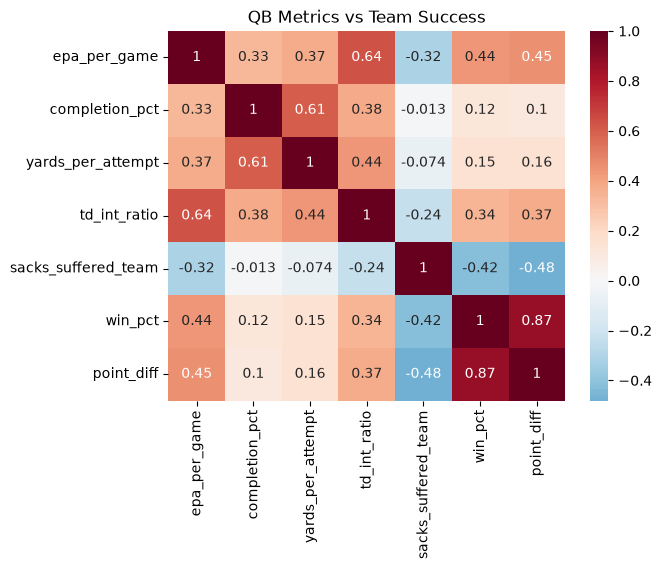

In [81]:
sns.heatmap(
    master_df[analysis_columns].corr(),
    annot=True,
    cmap="RdBu_r",
    center=0
)

plt.title("QB Metrics vs Team Success")
plt.show()